# Sprint 4: investigação de arquiteturas de CNN no Flowers102

Gabriel Fidalgo (RM563213), Pedro Lima (RM565461), Gustavo Maia (RM562240), Gustavo Rossi (RM566075)

Seguimos com a classificação de imagens da Sprint 3 (Flowers102, 102 classes, divisão oficial). Partimos de um baseline pequeno, mudamos um fator por vez e escolhemos a arquitetura pelo Validation. O Test só entra no final, uma vez.

Com os resultados já salvos em `results/`, o notebook roda em poucos minutos. Num clone limpo ele treina tudo (umas 3 h no Mac com MPS).

In [1]:
import os
import subprocess
import sys

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torchinfo import summary

from src import plots
from src.data import gera_splits, le_split, loaders
from src.evaluate import LOCK, agrega, evaluate_test, seleciona
from src.models import CNN, EXPERIMENTOS, monta_cfg
from src.train import treina
from src.utils import RESULTS, SEEDS, SPLITS, f3, fpar, le_json, set_seed, versoes

set_seed(42)  # mesma seed base do notebook da sprint 3
pd.set_option("display.width", 200)
print(versoes())

{'python': '3.14.7', 'torch': '2.14.1', 'torchvision': '0.29.1', 'numpy': '2.5.4', 'sklearn': '1.9.1', 'device': 'mps'}


## 1. Dados e divisão

O split é o oficial do `Flowers102` do torchvision, o mesmo da Sprint 3. Como ele só existia em memória, salvamos os caminhos de cada conjunto em `splits/*.csv` e conferimos com o `verifica_split.py`.

In [2]:
if not (SPLITS / "train.csv").exists():
    gera_splits()

for nome in ["train", "val", "test"]:
    print(nome, len(le_split(nome)))

print(subprocess.run([sys.executable, "scripts/verifica_split.py"], capture_output=True, text=True).stdout)

train 1020
val 1020
test 6149


PASS train tem 1020 imagens
PASS val tem 1020 imagens
PASS test tem 6149 imagens
PASS total 8189
PASS 102 classes
PASS train: 10 imagens por classe
PASS val: 10 imagens por classe
info: test por classe vai de 20 a 238
PASS train.csv igual ao Flowers102(split='train') da sprint 3 (caminhos e rotulos)
PASS val.csv igual ao Flowers102(split='val') da sprint 3 (caminhos e rotulos)
PASS test.csv igual ao Flowers102(split='test') da sprint 3 (caminhos e rotulos)
PASS sem interseccao de caminhos entre train e val
PASS sem interseccao de caminhos entre train e test
PASS sem interseccao de caminhos entre val e test
PASS hash do arquivo entre train e test: 1 duplicata(s), so as conhecidas do dataset original
PASS hash do arquivo entre val e test: 1 duplicata(s), so as conhecidas do dataset original
PASS hash do arquivo entre train e val: 0 duplicata(s), so as conhecidas do dataset original



Pré-processamento (o do relatório da Sprint 3): resize 256x256, recorte 224x224, normalização da ImageNet. No Train o recorte é aleatório e tem flip e rotação de até 30 graus. Val e Test usam recorte central.

O notebook da Sprint 3 só fazia `Resize((224, 224))`, sem o 256, mas o relatório descreve resize 256 + crop 224, então seguimos o relatório. O Train é balanceado (10 por classe), então não usamos `class_weight`.

In [3]:
train_loader, val_loader = loaders(seed=42)
x, y = next(iter(train_loader))
print(x.shape, y.shape, x.dtype)

torch.Size([32, 3, 224, 224]) torch.Size([32]) torch.uint8


## 2. Baseline

In [4]:
baseline = CNN(**monta_cfg("baseline"))
print(summary(baseline, input_size=(1, 3, 224, 224), device="cpu",
              col_names=("output_size", "num_params"), verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 102]                  --
├─Sequential: 1-1                        [1, 64, 28, 28]           --
│    └─Conv2d: 2-1                       [1, 16, 224, 224]         448
│    └─ReLU: 2-2                         [1, 16, 224, 224]         --
│    └─MaxPool2d: 2-3                    [1, 16, 112, 112]         --
│    └─Conv2d: 2-4                       [1, 32, 112, 112]         4,640
│    └─ReLU: 2-5                         [1, 32, 112, 112]         --
│    └─MaxPool2d: 2-6                    [1, 32, 56, 56]           --
│    └─Conv2d: 2-7                       [1, 64, 56, 56]           18,496
│    └─ReLU: 2-8                         [1, 64, 56, 56]           --
│    └─MaxPool2d: 2-9                    [1, 64, 28, 28]           --
├─Identity: 1-2                          [1, 64, 28, 28]           --
├─Sequential: 1-3                        [1, 102]                  --
│    └─

Quase todos os parâmetros do baseline estão na primeira Dense, por causa do Flatten de 50.176 valores. Isso importa nos experimentos de cabeça.

## 3. Experimentos

Cada linha muda uma coisa em relação ao baseline. A exceção é o `gap_bn`, que muda só o BatchNorm em relação ao `gap` e foi adicionado depois que o `batchnorm` não treinou. Protocolo fixo para todos: Adam, lr 5e-4, batch 32, até 50 épocas, parada pela acurácia do Validation (paciência 10), seeds 42, 43 e 44.

O lr 5e-4 saiu de um piloto pequeno (baseline, `kernel_5` e `batchnorm`, seed 42): com 1e-3 os dois últimos travaram no acaso. Os resultados dessa primeira rodada estão em `results/piloto_v1`.

In [5]:
pd.DataFrame([dict(experimento=n, mudanca=e["muda"], hipotese=e["hip"]) for n, e in EXPERIMENTOS.items()])

,experimento,mudanca,hipotese
0,baseline,Arquitetura inicial,"Ponto de partida: 3 blocos Conv-ReLU-MaxPool, ..."
1,prof_2,2 blocos conv (16-32),Com menos blocos o mapa fica maior antes do Fl...
2,prof_4,4 blocos conv (16-32-64-128),Um bloco a mais dá campo receptivo maior e red...
3,largura,Filtros 32-64-128,"Mais filtros por bloco, mais padrões de cor e ..."
4,kernel_5,Kernel 5x5,"Campo receptivo maior em cada camada, pode aju..."
5,stride,Conv com stride 2 no lugar do MaxPool,"Downsampling aprendido em vez de fixo, pra ver..."
6,gap,GlobalAveragePooling no lugar do Flatten,Corta quase todos os parâmetros da cabeça e po...
7,denso_256,Dense 256,Camada densa maior: mais capacidade ou só mais...
8,gap_bn,GAP + BatchNorm (muda só o BatchNorm em relaçã...,O BatchNorm foi mal com Flatten. Com a cabeça ...
9,batchnorm,BatchNorm depois de cada conv,Eixo separado. Deve estabilizar o treino e ace...


In [6]:
# se o json da rodada ja existe, o treino e pulado
for nome in EXPERIMENTOS:
    for s in SEEDS:
        treina(nome, s, verbose=False)
ag = agrega()
ag[["exp", "params", "n_seeds", "val_acc_mean", "val_acc_std", "val_f1_mean", "val_f1_std", "train_acc_mean", "diag"]].round(3)

,exp,params,n_seeds,val_acc_mean,val_acc_std,val_f1_mean,val_f1_std,train_acc_mean,diag
0,baseline,6459398,3,0.356,0.009,0.347,0.007,0.860,overfitting
1,prof_2,12863430,3,0.338,0.009,0.323,0.009,0.672,overfitting
2,prof_4,3321990,3,0.354,0.002,0.341,0.003,0.757,overfitting
3,largura,12951590,3,0.355,0.003,0.341,0.005,0.856,overfitting
4,kernel_5,6501126,3,0.312,0.013,0.296,0.016,0.696,overfitting
5,stride,6459398,3,0.320,0.017,0.306,0.020,0.795,overfitting
6,gap,45062,3,0.232,0.006,0.206,0.010,0.364,underfitting
7,denso_256,12895110,3,0.360,0.013,0.347,0.010,0.871,overfitting
8,gap_bn,45286,3,0.316,0.012,0.282,0.016,0.398,underfitting
9,batchnorm,6459622,3,0.043,0.030,0.015,0.017,0.035,underfitting


## 4. Resultados no Validation

In [7]:
resumo = ag[["exp", "muda", "params"]].copy()
resumo["params"] = resumo.params.map(fpar)
resumo["F1 macro (media +- desvio)"] = [f"{f3(m)} +- {f3(s)}" for m, s in zip(ag.val_f1_mean, ag.val_f1_std)]
resumo["precision"] = ag.val_precision_mean.map(f3)
resumo["recall"] = ag.val_recall_mean.map(f3)
resumo["melhor epoca"] = ag.melhor_epoca_mean.round(1)
resumo["tempo (s)"] = ag.tempo_s_mean.round(0).astype(int)
resumo["diagnostico"] = ag["diag"]
resumo

,exp,muda,params,F1 macro (media +- desvio),precision,recall,melhor epoca,tempo (s),diagnostico
0,baseline,Arquitetura inicial,6.459.398,"0,347 +- 0,007","0,376","0,356",46.0,202,overfitting
1,prof_2,2 blocos conv (16-32),12.863.430,"0,323 +- 0,009","0,345","0,338",47.0,202,overfitting
2,prof_4,4 blocos conv (16-32-64-128),3.321.990,"0,341 +- 0,003","0,371","0,354",44.0,436,overfitting
3,largura,Filtros 32-64-128,12.951.590,"0,341 +- 0,005","0,366","0,355",44.0,923,overfitting
4,kernel_5,Kernel 5x5,6.501.126,"0,296 +- 0,016","0,314","0,312",41.7,640,overfitting
5,stride,Conv com stride 2 no lugar do MaxPool,6.459.398,"0,306 +- 0,020","0,329","0,320",42.0,72,overfitting
6,gap,GlobalAveragePooling no lugar do Flatten,45.062,"0,206 +- 0,010","0,231","0,232",45.0,170,underfitting
7,denso_256,Dense 256,12.895.110,"0,347 +- 0,010","0,386","0,360",38.0,173,overfitting
8,gap_bn,GAP + BatchNorm (muda só o BatchNorm em relaçã...,45.286,"0,282 +- 0,016","0,287","0,316",44.3,210,underfitting
9,batchnorm,BatchNorm depois de cada conv,6.459.622,"0,015 +- 0,017","0,012","0,043",20.3,139,underfitting


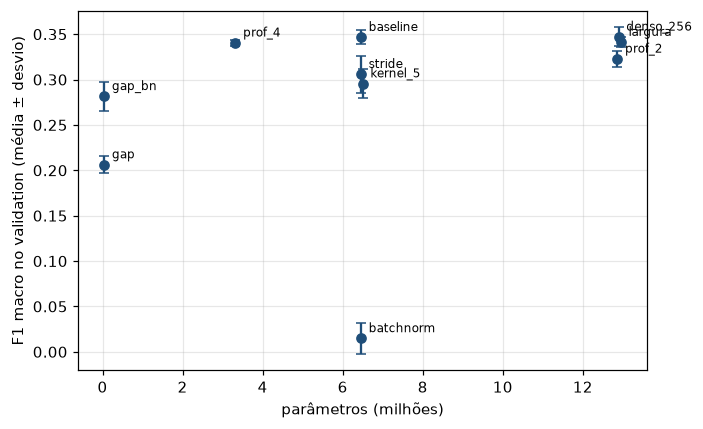

In [8]:
plots.val_vs_params(ag)
plt.show()

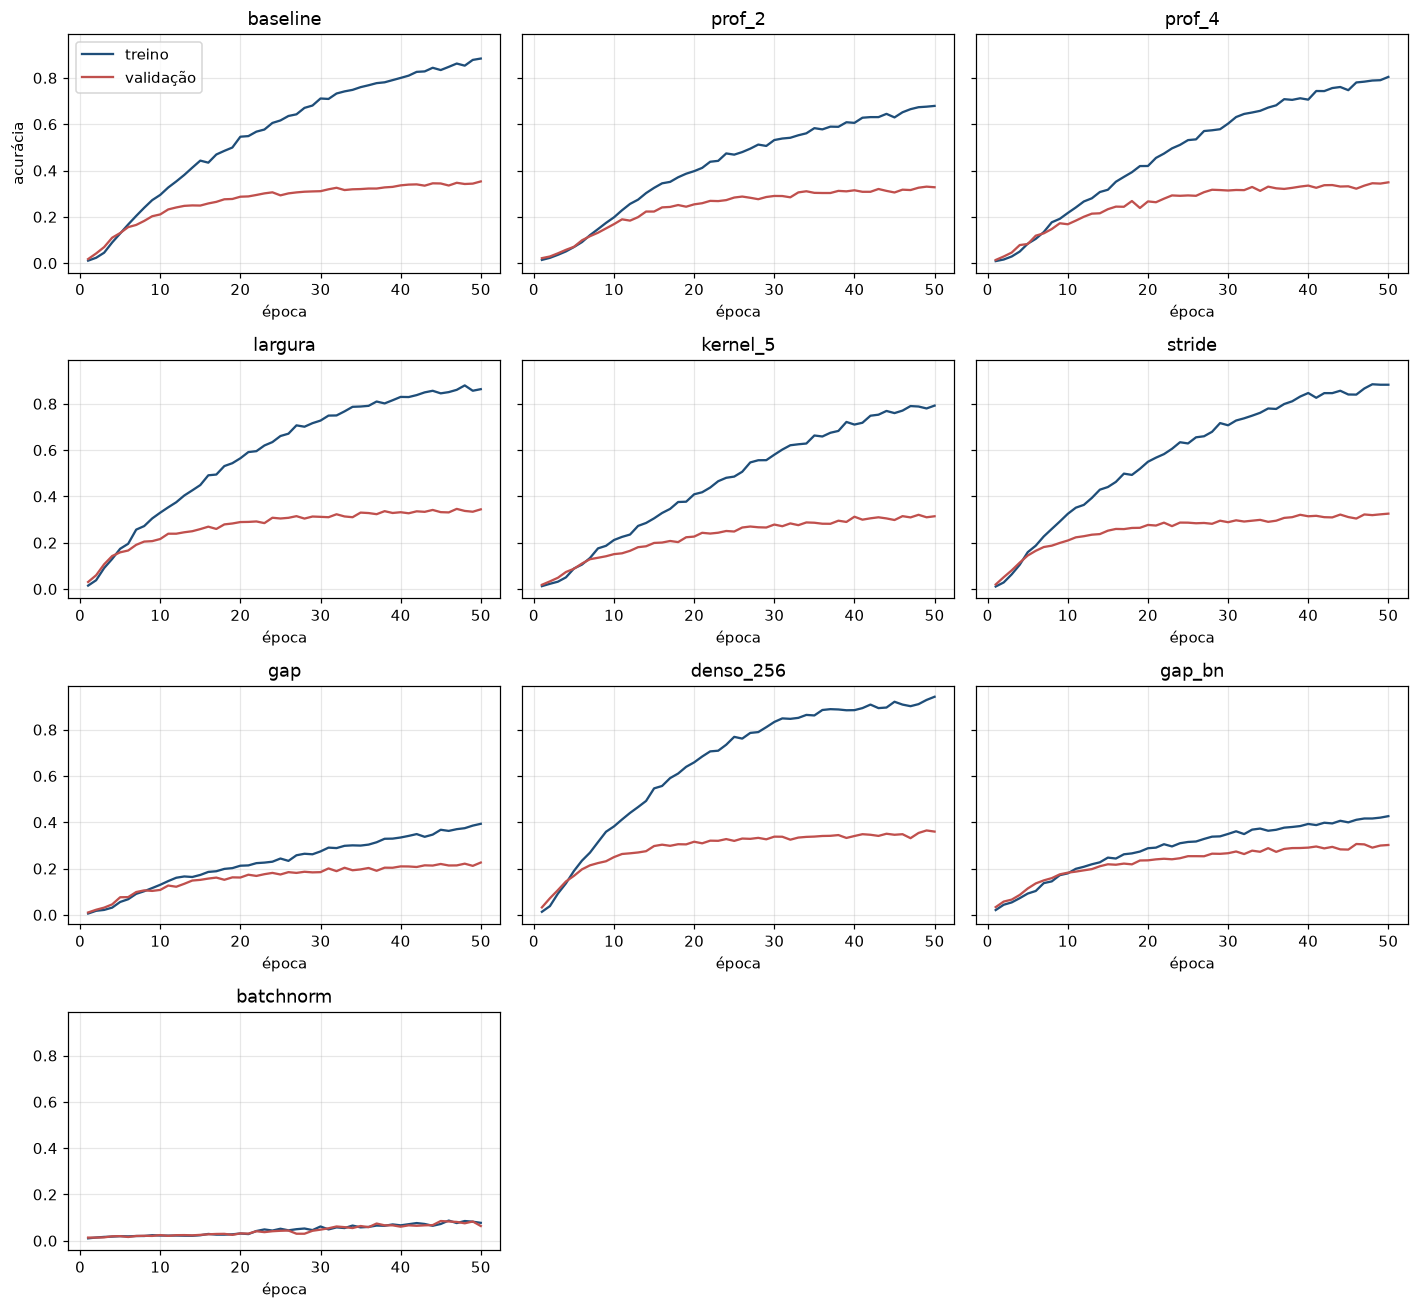

In [9]:
plots.todas_curvas()
plt.show()

Nas curvas (média das 3 seeds) os modelos com Flatten têm acurácia de treino bem acima da de validação, ou seja, overfitting. O `gap` e o `gap_bn` ficam com treino e validação parecidos e baixos, e isso lembra underfitting. O `batchnorm` não saiu do acaso.

Quando a diferença entre dois modelos é menor que o desvio entre seeds, não dá para dizer que um é melhor. Isso vale para baseline, `prof_4`, `largura` e `denso_256`.

In [10]:
top = ag.loc[ag.val_f1_mean.idxmax()]
empatados = ag[ag.val_f1_mean >= top.val_f1_mean - top.val_f1_std]
print("melhor F1 medio:", top.exp, f3(top.val_f1_mean), "desvio", f3(top.val_f1_std))
print("dentro de 1 desvio:", list(empatados.exp))
print("escolhida (menos parametros entre os empatados):", seleciona())

melhor F1 medio: denso_256 0,347 desvio 0,010
dentro de 1 desvio: ['baseline', 'prof_4', 'largura', 'denso_256']
escolhida (menos parametros entre os empatados): prof_4


A regra de seleção estava no código antes dos treinos: maior F1 macro médio e, entre os que ficam a menos de 1 desvio do melhor, o de menos parâmetros.

## 5. Test (uma avaliação só)

`evaluate_test()` escolhe sozinha o modelo pelo Validation, avalia as 3 seeds dele, grava `test_done.lock` e recusa uma segunda chamada. Se o lock já existe, o notebook só lê o que foi salvo.

In [11]:
if not LOCK.exists():
    evaluate_test()
else:
    print("test ja avaliado:", LOCK.read_text())

met = le_json(RESULTS / "test" / "metricas.json")
tab = pd.DataFrame(met["por_seed"]).T
tab.loc["media"] = tab.mean()
tab.round(3)

test ja avaliado: {
 "modelo": "prof_4",
 "seeds": [
  42,
  43,
  44
 ],
 "quando": "2026-10-23T19:45:25.370214"
}


,acc,precision,recall,f1
42,0.291,0.306,0.324,0.287
43,0.297,0.309,0.335,0.293
44,0.312,0.316,0.333,0.298
media,0.300,0.311,0.330,0.293


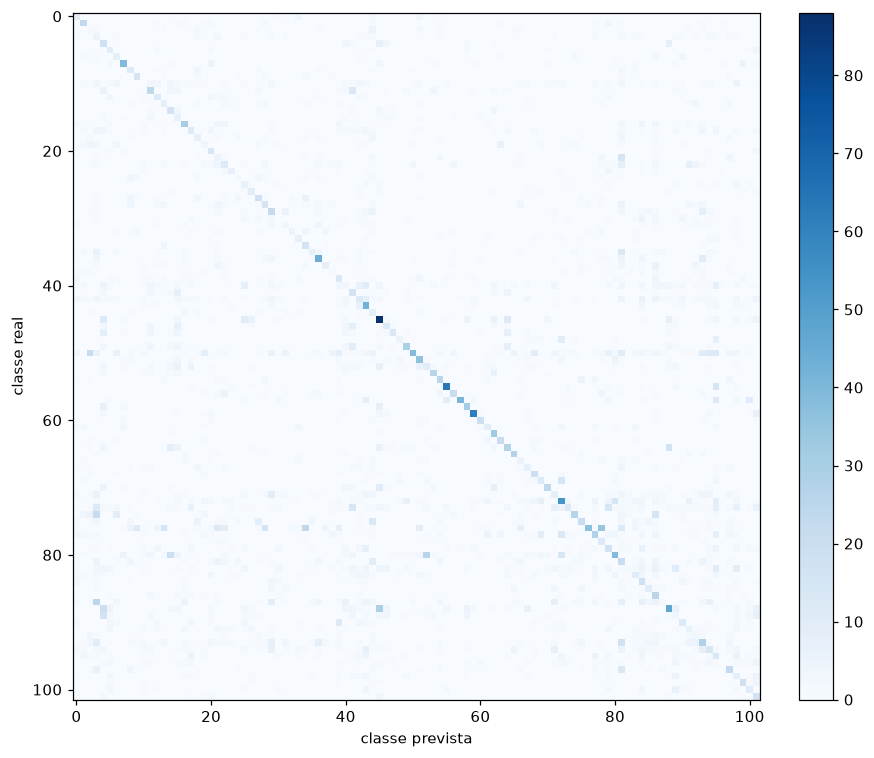

In [12]:
plots.matriz_confusao()
plt.show()

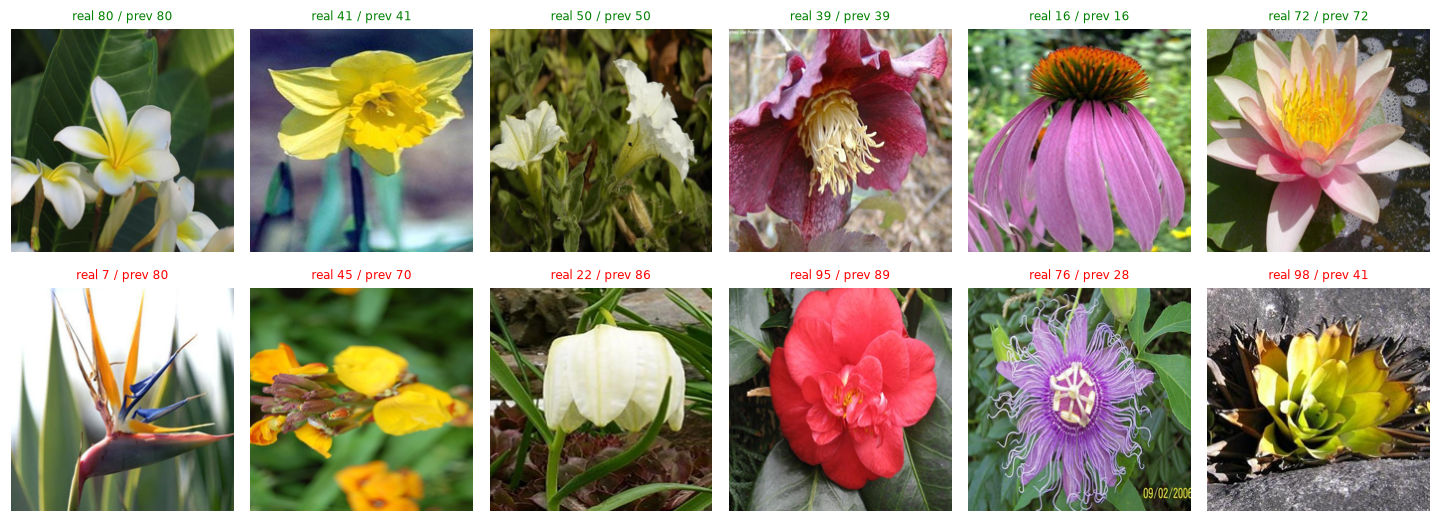

pares mais confundidos (real, previsto, imagens): [(76, 78, 35), (88, 45, 29), (80, 52, 26), (87, 3, 25), (76, 34, 24)]


,classe,precision,recall,f1,suporte
30,30,0.000,0.000,0.000,32
96,96,0.000,0.000,0.000,46
10,10,0.000,0.000,0.000,67
87,87,0.083,0.015,0.025,134
2,2,0.018,0.050,0.026,20


In [13]:
plots.grid_exemplos()
plt.show()
print("pares mais confundidos (real, previsto, imagens):", plots.pares_confundidos(5))
pc = pd.read_csv(RESULTS / "test" / "por_classe.csv")
pc.sort_values("f1").head(5).round(3)

## 6. Fechamento

Escolhemos o `prof_4` porque empatou com o baseline usando metade dos parâmetros. Os detalhes e as limitações estão nos slides e no README.